In [ ]:
import pandas as pd
import numpy as np

fuente = "../dataset/airfoil_self_noise.dat"
columnas = [
    "frequency",
    "angle",
    "chord_length",
    "velocity",
    "displacement",
    "sound_level"
]

df = pd.read_csv(
    fuente,
    sep="\t",
    header=None,
    names=columnas
)

print(df)

      frequency  angle  chord_length  velocity  displacement  sound_level
0           800    0.0        0.3048      71.3      0.002663      126.201
1          1000    0.0        0.3048      71.3      0.002663      125.201
2          1250    0.0        0.3048      71.3      0.002663      125.951
3          1600    0.0        0.3048      71.3      0.002663      127.591
4          2000    0.0        0.3048      71.3      0.002663      127.461
...         ...    ...           ...       ...           ...          ...
1498       2500   15.6        0.1016      39.6      0.052849      110.264
1499       3150   15.6        0.1016      39.6      0.052849      109.254
1500       4000   15.6        0.1016      39.6      0.052849      106.604
1501       5000   15.6        0.1016      39.6      0.052849      106.224
1502       6300   15.6        0.1016      39.6      0.052849      104.204

[1503 rows x 6 columns]


In [ ]:
x = df["frequency"].values
y = df["sound_level"].values

In [ ]:
X = np.column_stack([
    np.ones(len(x)),
    x,
    x**2
])

beta = np.linalg.lstsq(X, y, rcond=None)[0]

beta_0, beta_1, beta_2 = beta

print("Beta 0:", beta_0)
print("Beta 1:", beta_1)
print("Beta 2:", beta_2)

def prediccion_cuadratica(x):
    return beta_0 + beta_1*x + beta_2*x**2

Beta 0: 128.31041520374902
Beta 1: -0.001561198123823197
Beta 2: 5.649250938246676e-08


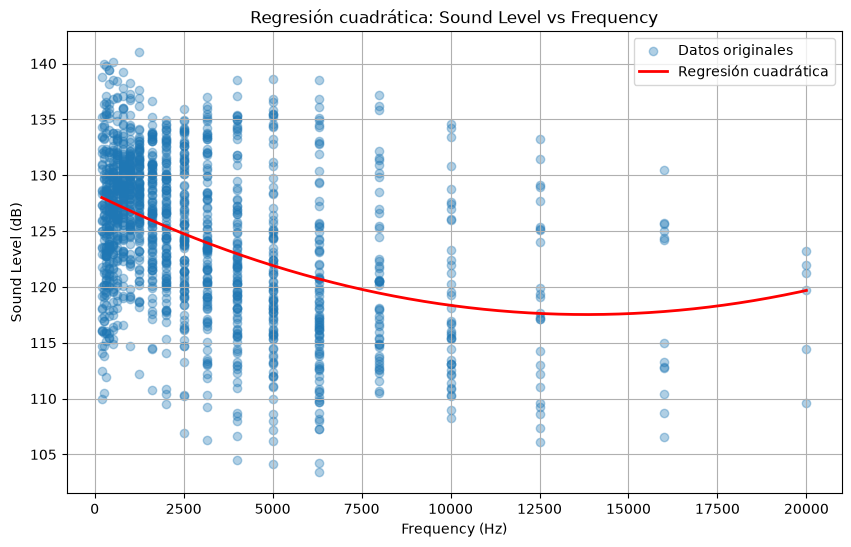

In [ ]:
"""
Prompt: Podrías darme una forma de ver graficamente los datos entre Frecuencia (eje x) y Sound Level (eje y) usando esto:
def prediccion_cuadratica(x):
    return beta_0 + beta_1*x + beta_2*x**2
    
x = df["frequency"].values
y = df["sound_level"].values
"""

import matplotlib.pyplot as plt

# Ordenamos las frecuencias para dibujar correctamente la curva
x_plot = np.linspace(x.min(), x.max(), 1503)
y_plot = prediccion_cuadratica(x_plot)

plt.figure(figsize=(10, 6))

plt.scatter(x, y, alpha=0.35, label="Datos originales")
plt.plot(x_plot, y_plot, color="red", linewidth=2,
         label="Regresión cuadrática")

plt.xlabel("Frequency (Hz)")
plt.ylabel("Sound Level (dB)")
plt.title("Regresión cuadrática: Sound Level vs Frequency")
plt.legend()
plt.grid()
plt.show()

In [ ]:
# 1. Calcular la derivada de la función cuadrática
def derivada_cuadratica(x):
    return beta_1 + 2 * beta_2 * x

# 2. Calcular para x = 12000 (Hz)
derivada_en_12000 = derivada_cuadratica(12000)
print("Cuando la frecuencia del sonido es de 12000 Hz, por cada 1 Hz adicional de frecuencia, el nivel de presión sonora varía aproximadamente en: ", derivada_en_12000,"dB/Hz")

# 3. Calcular para x = 7500 (Hz)
derivada_en_7500 = derivada_cuadratica(7500)
print("Cuando la frecuencia del sonido es de 7500 Hz, por cada 1 Hz adicional de frecuencia, el nivel de presión sonora varía aproximadamente en: ", derivada_en_7500,"dB/Hz")

Cuando la frecuencia del sonido es de 12000 Hz, por cada 1 Hz adicional de frecuencia, el nivel de presión sonora varía aproximadamente en:  -0.00020537789864399523 dB/Hz
Cuando la frecuencia del sonido es de 7500 Hz, por cada 1 Hz adicional de frecuencia, el nivel de presión sonora varía aproximadamente en:  -0.0007138104830861961 dB/Hz


In [19]:
"""
Hallar el punto crítico resolviendo dŷ/dx = 0, 
clasificarlo con la derivada segunda y determinar si cae dentro del rango de valores de frequency efectivamente observados.
Interpretar el resultado en el lenguaje del dominio."""
def derivada_segunda_cuadratica():
  return 2 * beta_2

def punto_critico():
  return -beta_1 / (2 * beta_2)


print("La derivada segunda es: ", derivada_segunda_cuadratica())

print("El punto crítico es: ", punto_critico())



La derivada segunda es:  1.1298501876493353e-07
El punto crítico es:  13817.744519486128
